# O Retrato da Rede: visualização racional com nxviz

> **Provocação inicial.** Pegue qualquer rede com mais de 50 nós e rode `nx.draw(G)`. O resultado tem nome na literatura: ***hairball***, a bola de pelos. E a bola de pelos tem um defeito mortal: rode o layout duas vezes e obtenha dois desenhos diferentes **da mesma rede**. O layout de força é um teste de Rorschach: cada um enxerga o que quiser, e nenhuma conclusão tirada dele sobrevive a uma segunda execução.
>
> A resposta da biblioteca [nxviz](https://github.com/ericmjl/nxviz), de Eric Ma, é uma ideia radical: **a posição de um nó não deve ser decidida por um simulador de molas, e sim declarada por você, a partir dos dados**. Visualização *racional* de redes: primeiro a geometria (onde cada nó tem o direito de estar), depois a estética (cor, tamanho, transparência mapeados a atributos), por último as anotações. Se dois alunos plotarem a mesma rede com as mesmas declarações, sai **o mesmo desenho, sempre**. Reprodutibilidade também é ciência.

Neste notebook vamos dissecar a nxviz por completo, usando as redes das nossas aulas: o grafo `a`–`i` da aula de caminhos, o grafo de 7 nós da aula de matrizes, o clube de karatê de Zachary e a rede de personagens de *Os Miseráveis*. O plano:

1. **A gramática** da nxviz: o *node table*, os `*_by` e a receita de 4 passos que gera todos os gráficos;
2. **Arc plot**: a rede em uma linha;
3. **Circos plot**: a linha vira círculo, o padrão de artigos científicos;
4. **Matrix plot**: a rede como imagem;
5. **Hive plot**: o retrato para quem já sabe o que procura;
6. **Geo plot**: quando o nó tem endereço, e o que fazer quando a biblioteca quebra (spoiler: vamos consertá-la em aula, usando a própria gramática);
7. **Grande final**: a mesma rede em cinco retratos lado a lado, e um circos **interativo** construído com o motor de layout da nxviz dentro do Plotly.

**Como usar:** os blocos **🧠 Pare e pense** pedem uma aposta antes da célula seguinte; os blocos **🔬 Por dentro da nxviz** abrem o capô da biblioteca.

In [1]:
# Instalação (só a primeira vez no Colab)
!pip install -q nxviz plotly

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 7.2 MB/s eta 0:00:00


In [2]:
import warnings
warnings.filterwarnings("ignore")   # a nxviz 0.7.x emite um aviso de API em transição

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import plotly.graph_objects as go

import nxviz as nv
from nxviz import annotate, highlights, layouts, lines, nodes, edges, utils

AZUL, LARANJA, VERDE, VERMELHO, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#b8b7b0"
print("NetworkX", nx.__version__)

NetworkX 3.6.1


## 1. A gramática: tudo é uma tabela + quatro verbos

A nxviz não pensa em "bolinhas e riscos". Ela pensa em **duas tabelas**:

* o **node table**: uma linha por nó, uma coluna por atributo;
* o **edge table**: uma linha por aresta, com `source`, `target` e os atributos da aresta.

Todo argumento terminado em `_by` (`group_by`, `sort_by`, `node_color_by`, `node_size_by`, `node_alpha_by`, `edge_lw_by`, `edge_color_by`, `edge_alpha_by`) **é o nome de uma coluna dessas tabelas**. Essa é a regra de ouro: *se você quer mapear algo no desenho, primeiro grave esse algo como atributo do grafo*. Métrica calculada e não gravada não existe para a nxviz.

A receita que gera **todos** os gráficos da biblioteca:

| Passo | O que declara | Argumentos |
|---|---|---|
| 1. Layout | a geometria: linha, círculo, grade, eixos | a função escolhida: `nv.arc`, `nv.circos`, `nv.matrix`, `nv.hive` |
| 2. Posição | *onde na geometria*: agrupar e ordenar | `group_by` (coluna categórica), `sort_by` (coluna quantitativa) |
| 3. Estética | cor, tamanho, transparência, espessura | `node_color_by`, `node_size_by`, `edge_lw_by`, ... |
| 4. Anotação | rótulos, legendas, realces | módulos `annotate` e `highlights` |

Vamos preparar as redes das aulas **já com as métricas gravadas como atributos**, para que virem colunas:

In [4]:
# ---- Rede 1: o grafo a-i da aula de caminhos e componentes ----
Gai = nx.Graph([("a","e"), ("e","d"), ("e","f"), ("d","f"), ("f","h"),
                ("f","g"), ("h","i"), ("h","b")])
Gai.add_node("c")

# ---- Rede 2: o grafo de 7 nós da aula de matrizes ----
A = np.array([[0,1,1,1,0,0,0],[1,0,1,0,1,1,0],[1,1,0,1,0,1,0],[1,0,1,0,0,1,0],
              [0,1,0,0,0,1,0],[1,1,1,1,1,0,1],[0,0,0,0,0,1,0]])
G7 = nx.relabel_nodes(nx.from_numpy_array(np.maximum(A, A.T)), {i: i+1 for i in range(7)})

# ---- Rede 3: o clube de karatê de Zachary (o atributo 'club' já vem gravado) ----
K = nx.karate_club_graph()

# ---- Rede 4: Os Miseráveis (arestas já têm 'weight' = capítulos em coautoria de cena) ----
LM = nx.les_miserables_graph()

# ---- Regra de ouro: calcular métricas E GRAVAR como atributos ----
for G in (Gai, G7, K, LM):
    nx.set_node_attributes(G, dict(G.degree()), "grau")
    nx.set_node_attributes(G, nx.clustering(G), "clustering")

# faixa categórica de grau (vamos precisar para agrupar)
for G in (K, LM):
    q1, q2 = np.quantile([d for _, d in G.degree()], [1/3, 2/3])
    nx.set_node_attributes(G, {n: ("hub" if d > q2 else "medio" if d > q1 else "periferico")
                               for n, d in G.degree()}, "faixa")

utils.node_table(K).head(6)   # o grafo visto como a nxviz o vê

,club,grau,clustering,faixa
0,Mr. Hi,16,0.150000,hub
1,Mr. Hi,9,0.333333,hub
2,Mr. Hi,10,0.244444,hub
3,Mr. Hi,6,0.666667,hub
4,Mr. Hi,3,0.666667,medio
5,Mr. Hi,4,0.500000,medio


Olhe a tabela acima: `club`, `grau`, `clustering` e `faixa` são colunas, e é **só isso** que a nxviz aceita nos `_by`. Repare também que o índice da tabela é o identificador do nó.

🔬 **Por dentro da nxviz.** `utils.node_table(G)` e `utils.edge_table(G)` são a fundação de tudo: internamente, cada função de layout recebe o *node table*, agrupa por `group_by`, ordena por `sort_by` e devolve um dicionário `nó -> (x, y)`. Cada função de estética recebe a mesma tabela e devolve uma série de cores/tamanhos/alfas. O desenho final é matplotlib puro: círculos (`Circle`) para nós e curvas de Bézier (`Path`) para arestas, adicionados ao eixo atual com `plt.gca()`. Consequência prática que usaremos o tempo todo: **um plot da nxviz convive com qualquer figura matplotlib**, inclusive em `subplots`.

## 2. Arc plot: a rede em uma linha

O arc plot é a geometria mais simples que existe: **todos os nós em uma reta**, arestas como semicírculos por cima. Parece humilde, mas tem uma superpotência: a reta tem **ordem**, e ordem é informação. Ordenar por grau põe os hubs de um lado; ordenar por clustering separa os "panelinhas" dos "pontes".

Duas regras de leitura:

* **arco longo** = aresta entre nós distantes na ordenação = conexão "improvável" segundo o critério de ordenação;
* **feixe de arcos convergindo** em um ponto = hub.

🧠 **Pare e pense.** Vamos plotar o grafo `a`–`i` ordenado por grau (crescente da esquerda para a direita). Onde vai parar o nó `f`, que tem grau 4? E o isolado `c`, que aparência terá?

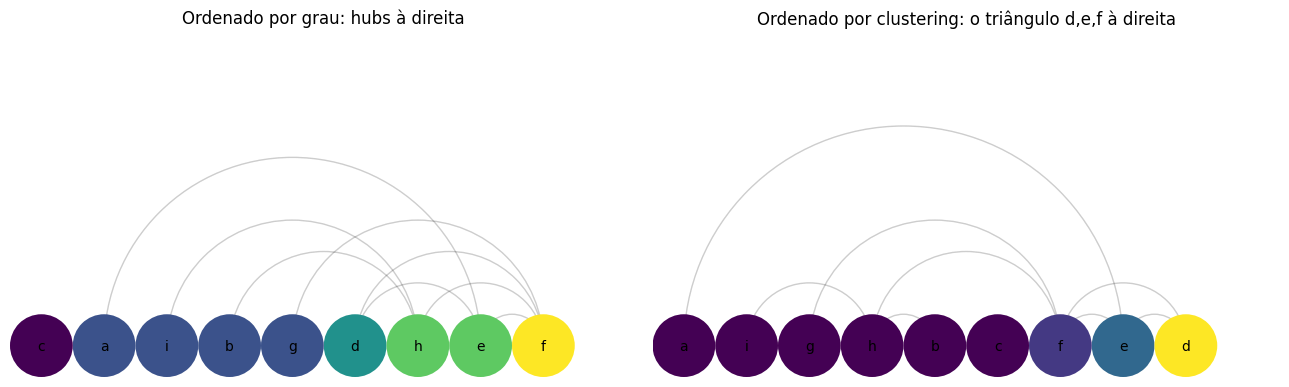

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plt.sca(axes[0])
nv.arc(Gai, sort_by="grau", node_color_by="grau")
annotate.arc_labels(Gai, sort_by="grau")
axes[0].set_title("Ordenado por grau: hubs à direita")

plt.sca(axes[1])
nv.arc(Gai, sort_by="clustering", node_color_by="clustering")
annotate.arc_labels(Gai, sort_by="clustering")
axes[1].set_title("Ordenado por clustering: o triângulo d,e,f à direita")

plt.tight_layout(); plt.show()

O mesmo grafo, duas perguntas, dois retratos, e os dois **determinísticos**: qualquer colega que rodar esta célula verá exatamente isto. Compare com o `nx.draw` da aula passada.

### 2.1 Realce: o WikiGame no arc plot

O módulo `highlights` desenha por cima do plot, e é perfeito para contar histórias: vamos destacar o caminho mínimo `a → b` daquela aula (`a-e-f-h-b`), aresta por aresta. Note o detalhe técnico: `highlights.arc_edge` **só aceita arestas que existem no grafo**, então destacamos um caminho percorrendo seus pares consecutivos.

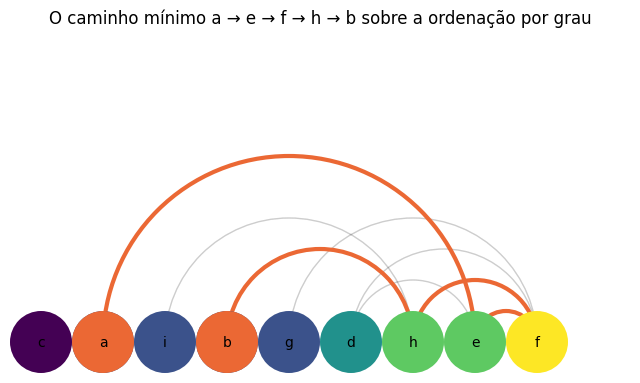

In [6]:
plt.figure(figsize=(8, 4.5))
nv.arc(Gai, sort_by="grau", node_color_by="grau")

caminho = nx.shortest_path(Gai, "a", "b")
for u, v in zip(caminho, caminho[1:]):
    highlights.arc_edge(Gai, u, v, sort_by="grau", color=LARANJA, lw=3)
for n in (caminho[0], caminho[-1]):
    highlights.arc_node(Gai, n, sort_by="grau", color=LARANJA)
annotate.arc_labels(Gai, sort_by="grau")   # rótulos por último, para ficarem por cima dos realces

plt.title(f"O caminho mínimo {' → '.join(caminho)} sobre a ordenação por grau")
plt.show()

🧠 **Pare e pense.** No desenho acima, o caminho mínimo usa só arcos curtos ou precisa de arcos longos? O que isso diz sobre a relação entre "andar pela rede" e "andar pela ordenação de grau"? *(Dica: para ir de um nó periférico a outro, por onde é quase obrigatório passar?)*

## 3. Circos plot: a linha vira círculo

Dobre a reta do arc plot até as pontas se encontrarem: nasce o **circos plot**, herdeiro do software Circos da genômica (mapas de cromossomos) e hoje o formato favorito de papers com redes grandes. A vantagem sobre o arc: nenhum nó é "ponta", e arestas viram cordas cujo comprimento visual é comparável em qualquer direção.

O circos brilha de verdade quando existe **grupo**. Com `group_by`, a nxviz reserva um setor do círculo para cada categoria, e a pergunta estrutural fica visível de imediato: *as cordas ficam dentro dos setores ou cruzam o centro?*

Rede da vez: o clube de karatê, agrupado pela facção real (`club`), com um arsenal completo de estética: ordenação por grau dentro de cada setor, tamanho por grau, cor pela facção (com paleta nossa, via `node_palette`), transparência das arestas para não virar bola de pelos.

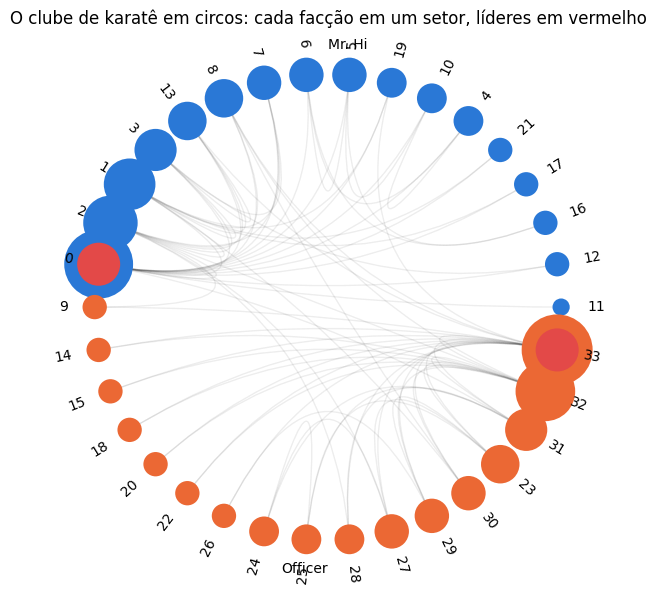

In [7]:
plt.figure(figsize=(7.5, 7.5))
nv.circos(K,
          group_by="club", sort_by="grau",
          node_color_by="club", node_size_by="grau",
          node_palette={"Mr. Hi": AZUL, "Officer": LARANJA},
          node_enc_kwargs={"size_scale": 0.4},
          edge_enc_kwargs={"alpha_scale": 0.35})
annotate.circos_group(K, group_by="club")
annotate.circos_labels(K, group_by="club", sort_by="grau", layout="rotate")

# os dois líderes, realçados
highlights.circos_node(K, 0, group_by="club", sort_by="grau", color=VERMELHO)
highlights.circos_node(K, 33, group_by="club", sort_by="grau", color=VERMELHO)

plt.title("O clube de karatê em circos: cada facção em um setor, líderes em vermelho")
plt.show()

Leitura: dentro de cada setor, os nós crescem de grau até culminar no líder (realçado); a maioria das cordas vive **dentro** do próprio setor, e as poucas que cruzam o centro são exatamente as pontes diplomáticas que cortamos na aula de componentes. O racha está desenhado.

🔬 **Por dentro da nxviz.** Três minúcias que separam o usuário casual do avançado:

1. `node_palette` aceita um **dicionário categoria → cor** (nosso caso) ou uma lista. Sem ele, a nxviz usa uma paleta padrão por ordem alfabética das categorias, e suas cores mudam se você renomear um grupo: grave a paleta explícita em material didático.
2. `node_enc_kwargs={"size_scale": ...}` e `edge_enc_kwargs={"alpha_scale": ...}` são multiplicadores globais aplicados **depois** do mapeamento `_by`: o jeito rápido de calibrar um desenho sem mexer nos dados.
3. `annotate.circos_labels(..., layout="rotate")` gira cada rótulo para acompanhar o raio; as alternativas são `"standard"` e `"numbers"` (esta última numera os nós e imprime a legenda ao lado, ótima para redes com nomes longos).

### 3.1 Os Miseráveis: estética de aresta carregando a história

Agora uma rede maior (77 personagens) e uma pergunta diferente: não *quem conhece quem*, mas **quais laços sustentam o romance**. A espessura da corda (`edge_lw_by="weight"`) é o número de capítulos em que os dois personagens dividem cena.

🧠 **Pare e pense.** Você espera que as cordas grossas fiquem entre dois hubs, ou entre um hub e um coadjuvante? Aposte em um par específico antes de rodar.

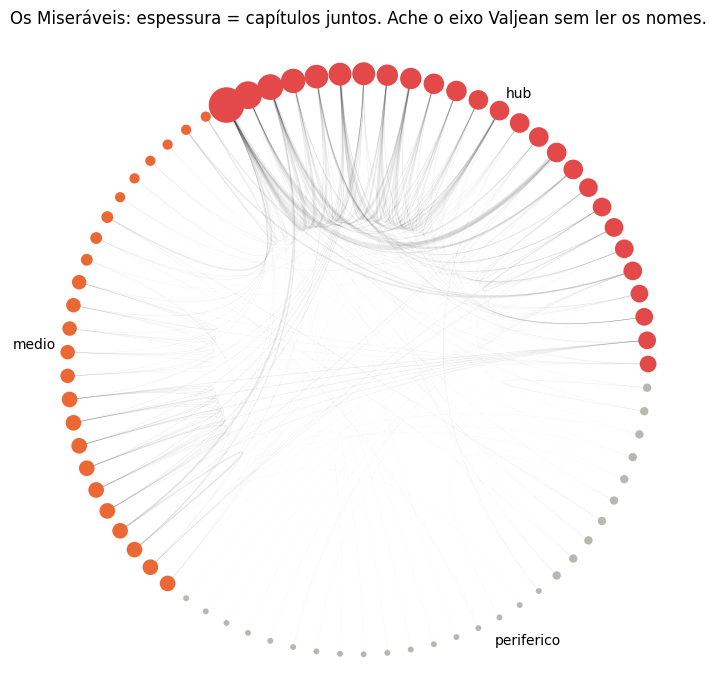

As 5 relações mais fortes do romance:
   Valjean — Cosette: 31 capítulos
   Cosette — Marius: 21 capítulos
   Valjean — Marius: 19 capítulos
   Valjean — Javert: 17 capítulos
   Enjolras — Courfeyrac: 17 capítulos


In [8]:
plt.figure(figsize=(8.5, 8.5))
nv.circos(LM,
          group_by="faixa", sort_by="grau",
          node_color_by="faixa", node_size_by="grau",
          node_palette={"hub": VERMELHO, "medio": LARANJA, "periferico": CINZA},
          node_enc_kwargs={"size_scale": 0.25},
          edge_lw_by="weight",
          edge_enc_kwargs={"alpha_scale": 0.4, "lw_scale": 0.12})
annotate.circos_group(LM, group_by="faixa")
plt.title("Os Miseráveis: espessura = capítulos juntos. Ache o eixo Valjean sem ler os nomes.")
plt.show()

pesos = sorted(((d["weight"], u, v) for u, v, d in LM.edges(data=True)), reverse=True)[:5]
print("As 5 relações mais fortes do romance:")
for w, u, v in pesos:
    print(f"   {u} — {v}: {w} capítulos")

## 4. Matrix plot: a rede como imagem

Da aula de passeios e matrizes: um grafo **é** sua matriz de adjacência. O matrix plot desenha exatamente isso, célula `(i,j)` pintada se a aresta existe, e herda as duas regras da gramática: `group_by` **ordena as linhas e colunas por grupo**, e é aí que mora a mágica.

Primeiro, fidelidade ao slide da aula: o grafo de 7 nós.

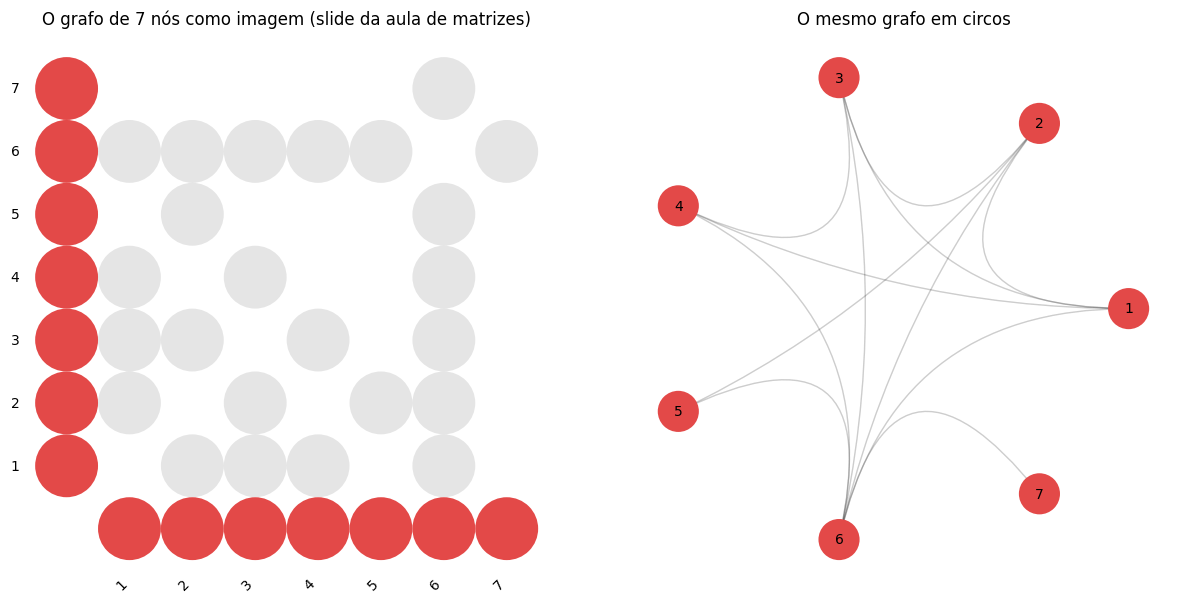

In [9]:
G7.add_nodes_from(G7.nodes())   # garantia de ordem estável
for n in G7:
    G7.nodes[n]["tudo"] = "rede"

fig, axes = plt.subplots(1, 2, figsize=(12.5, 6))
plt.sca(axes[0])
nv.matrix(G7, group_by="tudo", node_color_by="tudo", node_palette=[VERMELHO])
annotate.matrix_labels(G7, group_by="tudo", layout="standard")
axes[0].set_title("O grafo de 7 nós como imagem (slide da aula de matrizes)")

plt.sca(axes[1])
nv.circos(G7, group_by="tudo", node_color_by="tudo",
          node_enc_kwargs={"radius": 0.2}, node_palette=[VERMELHO])
annotate.circos_labels(G7, group_by="tudo")
axes[1].set_title("O mesmo grafo em circos")
plt.tight_layout(); plt.show()

🧠 **Pare e pense.** No matrix plot, a diagonal principal está vazia. O que uma célula pintada na diagonal significaria? E por que a imagem é simétrica em relação à diagonal? Em que tipo de grafo ela deixaria de ser?

Agora o golpe de mestre: o clube de karatê com linhas e colunas **agrupadas por facção**. Numa matriz bem ordenada, comunidade vira **bloco**.

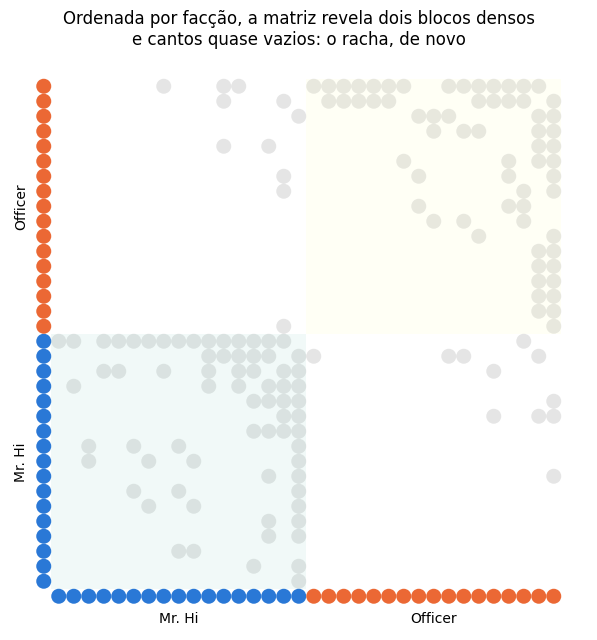

In [10]:
plt.figure(figsize=(7.5, 7.5))
nv.matrix(K, group_by="club", sort_by="grau", node_color_by="club",
          node_palette={"Mr. Hi": AZUL, "Officer": LARANJA})
annotate.matrix_block(K, group_by="club", color_by="club", alpha=0.12)
annotate.matrix_group(K, group_by="club")
plt.title("Ordenada por facção, a matriz revela dois blocos densos\ne cantos quase vazios: o racha, de novo")
plt.show()

Os dois quadrados coloridos (via `annotate.matrix_block`) marcam os blocos diagonais: arestas **dentro** de cada facção. Os cantos fora dos blocos são as pontes entre facções, poucas e preciosas. Este é o mesmo diagnóstico do circos da Seção 3, mas em uma forma que **escala**: um matrix plot de 10 mil nós ainda é legível como textura (blocos = comunidades, linhas densas = hubs), enquanto qualquer desenho de bolinhas já colapsou muito antes.

🔬 **Por dentro da nxviz.** A ordem das linhas é `group_by` primeiro, `sort_by` dentro do grupo, e essa dupla é o **único** grau de liberdade do matrix plot: matrizes de adjacência não têm layout, têm *permutação*. Reordenar linhas/colunas para revelar blocos é um campo inteiro (procure por *matrix seriation*). Para grafos dirigidos, a nxviz usa o eixo clonado (`cloned_node_layout_kwargs`) para separar "linha = origem" de "coluna = destino"; a assimetria da imagem passa a carregar informação.

## 5. Hive plot: o retrato para quem já sabe a pergunta

O hive plot é o mais opinado dos layouts: **até três eixos radiais**, um por categoria; cada nó vive no eixo do seu grupo, na posição dada por `sort_by`; as arestas viram curvas entre eixos. Ele foi criado (por Martin Krzywinski, o mesmo do Circos) como resposta direta à bola de pelos: um desenho onde **cada elemento tem posição justificável**.

A leitura exige treino, e é por isso que ele impressiona em artigo:

* curvas **entre eixos diferentes** = arestas entre grupos;
* para arestas **dentro do mesmo grupo**, a nxviz desdobra o eixo em dois meios-eixos gêmeos e liga um ao outro (senão a curva degeneraria numa reta sobre o próprio eixo);
* a posição radial é o `sort_by`: nós perto do centro têm valor baixo.

Vamos usar as faixas de grau do karatê (`hub`, `medio`, `periferico`), com a posição radial dada pelo **clustering**, cruzando as duas métricas da aula de "amigo do amigo" em um único retrato.

🧠 **Pare e pense.** Hubs tendem a ter clustering alto ou baixo? *(Lembre da fórmula: $C(i) = 2\tau(i) / (k_i(k_i-1))$: o denominador cresce com o quadrado do grau.)* Então: os nós do eixo "hub" vão se acumular perto ou longe do centro?

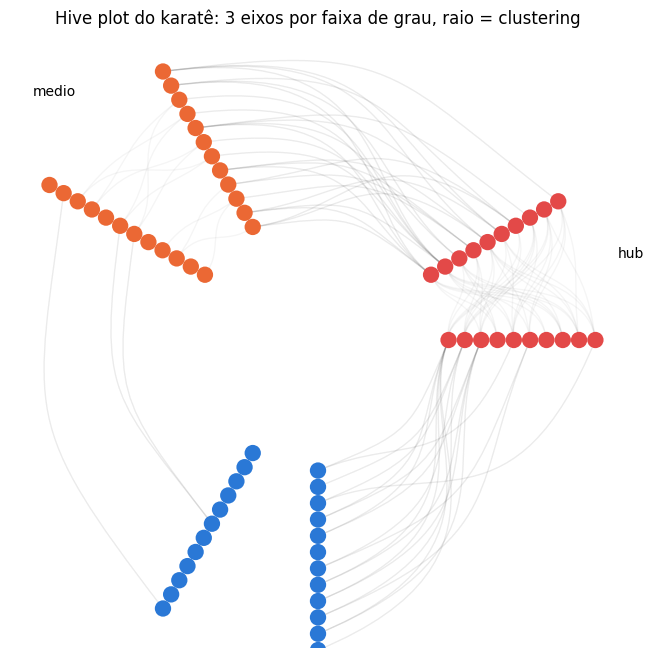

            grau  clustering
faixa                       
hub         9.10        0.34
medio       3.50        0.50
periferico  1.92        0.83


In [11]:
plt.figure(figsize=(8, 8))
nv.hive(K, group_by="faixa", sort_by="clustering",
        node_color_by="faixa",
        node_palette={"hub": VERMELHO, "medio": LARANJA, "periferico": AZUL},
        edge_enc_kwargs={"alpha_scale": 0.4})
annotate.hive_group(K, group_by="faixa")
plt.title("Hive plot do karatê: 3 eixos por faixa de grau, raio = clustering")
plt.show()

tab = utils.node_table(K).groupby("faixa")[["grau", "clustering"]].mean().round(2)
print(tab)

A tabela confirma o desenho: quanto maior a faixa de grau, menor o clustering médio. Hubs são **pontes entre panelinhas**, não membros de panelinha, e o hive plot mostra isso geometricamente: o eixo dos hubs povoado perto do centro (clustering baixo) e conectado a todos os outros.

⚠️ **Limite de projeto**: o hive plot aceita **no máximo 3 grupos** (mais eixos tornariam pares de eixos não adjacentes ilegíveis). Se sua variável tem 4+ categorias, agregue antes, ou use circos com `group_by`.

## 6. Geo plot: quando o nó tem endereço, e o dia em que a biblioteca quebrou

Se cada nó tem `latitude` e `longitude`, a geometria não é mais escolha: é o mapa. Vamos montar uma mini malha aérea brasileira (aeroportos e rotas, com o número de voos diários como peso), no espírito das *transport networks* da aula de redes complexas.

Mas aqui este notebook fica sincero de propósito: **na versão 0.7.6 da nxviz, `nv.geo` está quebrado** (as posições saem como `pandas.Series`, e o matplotlib espera arrays; o `Circle` explode com `KeyError: 0`). Você pode conferir descomentando a linha indicada.

E agora? Agora a filosofia da biblioteca paga o investimento. Como o plot de alto nível é só uma **composição** (layout → nós → arestas), podemos montar o geo plot **com as peças de médio nível**: `nodes.draw` + `edges.draw` + uma função de layout nossa de 3 linhas. É o mesmo mecanismo interno; nós apenas trocamos a peça defeituosa.

In [12]:
BR = nx.Graph()
aeroportos = {   # (latitude, longitude) aproximadas
    "NAT": (-5.91, -35.25), "REC": (-8.13, -34.92), "FOR": (-3.78, -38.53),
    "SSA": (-12.91, -38.32), "BSB": (-15.87, -47.92), "GIG": (-22.81, -43.25),
    "GRU": (-23.43, -46.47), "MAO": (-3.04, -60.05), "POA": (-29.99, -51.17),
}
regiao = {"NAT": "Nordeste", "REC": "Nordeste", "FOR": "Nordeste", "SSA": "Nordeste",
          "BSB": "Centro-Oeste", "GIG": "Sudeste", "GRU": "Sudeste",
          "MAO": "Norte", "POA": "Sul"}
for sigla, (lat, lon) in aeroportos.items():
    BR.add_node(sigla, latitude=lat, longitude=lon, regiao=regiao[sigla])

rotas = [("NAT","REC",8), ("NAT","GRU",4), ("NAT","BSB",3), ("REC","GRU",12), ("FOR","GRU",10),
         ("FOR","BSB",6), ("SSA","GRU",9), ("SSA","BSB",6), ("GRU","BSB",20), ("GRU","GIG",25),
         ("GRU","MAO",7), ("GRU","POA",14), ("BSB","MAO",5), ("BSB","GIG",11), ("REC","FOR",5)]
BR.add_weighted_edges_from(rotas, weight="voos")
nx.set_node_attributes(BR, dict(BR.degree()), "grau")

# nv.geo(BR)   # <- descomente para ver o KeyError: 0 da versão 0.7.6

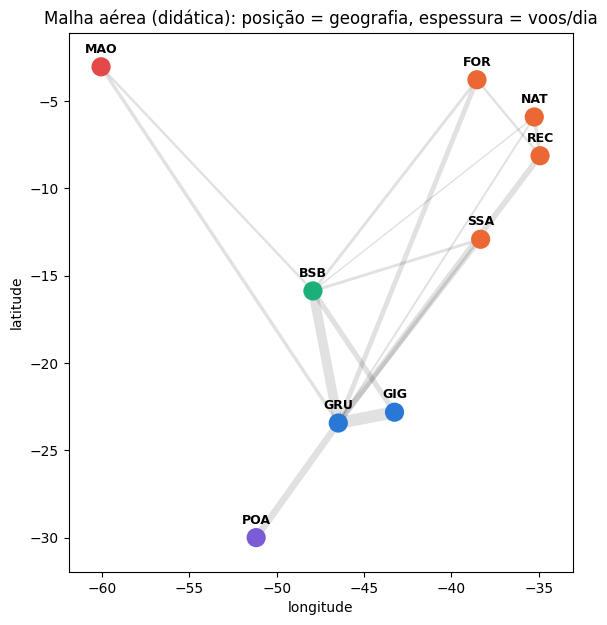

In [13]:
# O conserto: um geo plot montado com a API de camadas da própria nxviz
def layout_geo(nt, group_by, sort_by, **kwargs):
    '''Função de layout no contrato da nxviz: recebe o node table, devolve nó -> (x, y).
       A original devolve pandas.Series; devolvemos np.array, e o bug morre.'''
    return {n: np.array([d["longitude"], d["latitude"]]) for n, d in nt.iterrows()}

fig, ax = plt.subplots(figsize=(7, 7))
pos = nodes.draw(BR, layout_func=layout_geo, group_by=None, sort_by=None,
                 color_by="regiao",
                 palette={"Nordeste": LARANJA, "Sudeste": AZUL, "Centro-Oeste": VERDE,
                          "Norte": VERMELHO, "Sul": "#7b5cd6"},
                 encodings_kwargs={"size_scale": 0.55})
edges.draw(BR, pos, lines_func=lines.line, lw_by="voos",
           encodings_kwargs={"lw_scale": 0.35, "alpha_scale": 0.6})
for n, (x, y) in pos.items():
    ax.text(x, y + 0.8, n, ha="center", fontsize=9, fontweight="bold")

ax.set_aspect("equal"); ax.relim(); ax.autoscale_view()
ax.set_title("Malha aérea (didática): posição = geografia, espessura = voos/dia")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
plt.show()

🔬 **Por dentro da nxviz (a lição inteira em um parágrafo).** O que acabamos de fazer é o *design* da biblioteca funcionando como prometido. `nodes.draw` recebe **qualquer** função com a assinatura `f(node_table, group_by, sort_by, **kwargs) -> dict nó -> (x, y)`; as funções oficiais em `nxviz.layouts` (`arc`, `circos`, `matrix`, `hive`, `geo`, `parallel`) seguem todas esse contrato, e a nossa `layout_geo` também. `edges.draw` recebe o dicionário de posições e uma função de traçado de `nxviz.lines` (`line` reta, `arc`, `circos` Bézier pelo centro, `matrix`, `hive`). Ou seja: **você pode inventar uma geometria nova para redes escrevendo uma função de meia dúzia de linhas**, e ganhar de graça todo o sistema de estética `_by`. Poucas bibliotecas entregam extensibilidade tão barata; é isso que "gramática de gráficos" significa na prática.

🧠 **Pare e pense.** A régua do mapa mente: 1 grau de longitude perto do equador (MAO) e no sul (POA) têm comprimentos diferentes em km. Para uma malha aérea nacional isso importa pouco; em que tipo de análise de rede geográfica isso viraria um erro grave? Que projeção você usaria no lugar?

## 7. Grande final, parte 1: a mesma rede, cinco retratos

O antídoto definitivo contra o teste de Rorschach: aprender a olhar **a mesma rede** por todas as geometrias, sabendo o que cada uma esconde e revela. Karatê, cinco vezes, com as mesmas cores (azul/laranja = facção) e a mesma ordenação (grau):

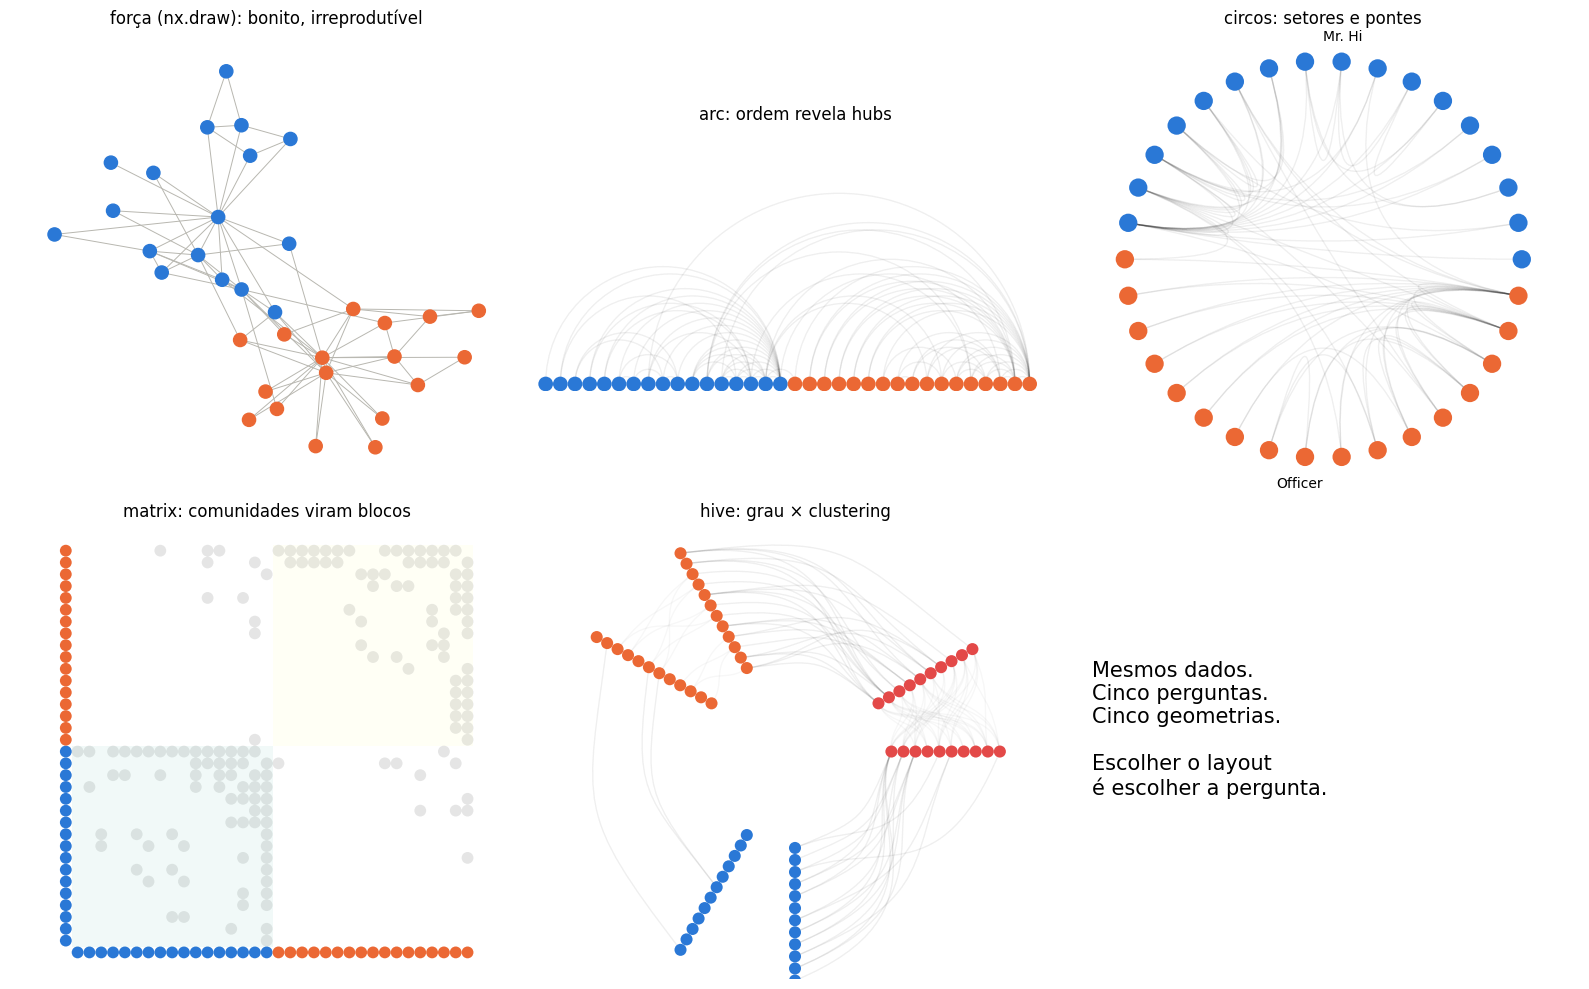

In [14]:
PAL = {"Mr. Hi": AZUL, "Officer": LARANJA}
fig = plt.figure(figsize=(16, 10))

ax1 = plt.subplot(2, 3, 1); plt.sca(ax1)
pos_spring = nx.spring_layout(K, seed=42)
nx.draw_networkx(K, pos=pos_spring, ax=ax1, node_size=90, with_labels=False,
                 node_color=[PAL[K.nodes[n]["club"]] for n in K], edge_color=CINZA, width=0.7)
ax1.set_title("força (nx.draw): bonito, irreprodutível"); ax1.axis("off")

ax2 = plt.subplot(2, 3, 2); plt.sca(ax2)
nv.arc(K, group_by="club", sort_by="grau", node_color_by="club", node_palette=PAL,
       edge_enc_kwargs={"alpha_scale": 0.3})
ax2.set_title("arc: ordem revela hubs")

ax3 = plt.subplot(2, 3, 3); plt.sca(ax3)
nv.circos(K, group_by="club", sort_by="grau", node_color_by="club", node_palette=PAL,
          node_enc_kwargs={"size_scale": 0.5}, edge_enc_kwargs={"alpha_scale": 0.3})
annotate.circos_group(K, group_by="club")
ax3.set_title("circos: setores e pontes")

ax4 = plt.subplot(2, 3, 4); plt.sca(ax4)
nv.matrix(K, group_by="club", sort_by="grau", node_color_by="club", node_palette=PAL)
annotate.matrix_block(K, group_by="club", color_by="club", alpha=0.12)
ax4.set_title("matrix: comunidades viram blocos")

ax5 = plt.subplot(2, 3, 5); plt.sca(ax5)
nv.hive(K, group_by="faixa", sort_by="clustering", node_color_by="faixa",
        node_palette={"hub": VERMELHO, "medio": LARANJA, "periferico": AZUL},
        edge_enc_kwargs={"alpha_scale": 0.3})
ax5.set_title("hive: grau × clustering")

ax6 = plt.subplot(2, 3, 6); ax6.axis("off")
ax6.text(0.05, 0.55, "Mesmos dados.\nCinco perguntas.\nCinco geometrias.\n\n"
                     "Escolher o layout\né escolher a pergunta.",
         fontsize=15, va="center")
plt.tight_layout(); plt.show()

## 8. Grande final, parte 2: um circos interativo (nxviz por dentro do Plotly)

Os plots da nxviz são estáticos por vocação (figuras de artigo). Mas a Seção 6 nos ensinou que o **motor de layout** é separável do desenho. Então vamos ao golpe ousado: pedir à nxviz **apenas as coordenadas** (`layouts.circos`, o mesmo código que posicionou os nós da Seção 3) e desenhá-las no **Plotly**, com hover, zoom e as cordas curvadas para o centro como no circos verdadeiro (Bézier quadrático com controle na origem, que é exatamente o que `nxviz.lines.circos` faz em matplotlib).

O resultado: o rigor da geometria declarativa + a exploração interativa. Passe o mouse em qualquer membro do clube.

In [15]:
# 1) o motor de layout da nxviz
nt = utils.node_table(K)
pos_cx = layouts.circos(nt, group_by="club", sort_by="grau")

# 2) cordas: Bézier quadrático p0 -> centro -> p1 (30 pontos por corda)
def corda(p0, p1, curvatura=0.7, k=30):
    t = np.linspace(0, 1, k)[:, None]
    ctrl = (p0 + p1) / 2 * (1 - curvatura)          # controle puxado para a origem
    pts = (1 - t)**2 * p0 + 2 * (1 - t) * t * ctrl + t**2 * p1
    return pts

figI = go.Figure()
for u, v in K.edges():
    pts = corda(np.asarray(pos_cx[u], float), np.asarray(pos_cx[v], float))
    entre = K.nodes[u]["club"] != K.nodes[v]["club"]
    figI.add_scatter(x=pts[:, 0], y=pts[:, 1], mode="lines",
                     line=dict(color=VERMELHO if entre else CINZA,
                               width=2.2 if entre else 0.8),
                     opacity=0.9 if entre else 0.45, hoverinfo="skip", showlegend=False)

PAL = {"Mr. Hi": AZUL, "Officer": LARANJA}
ns = list(K.nodes())
figI.add_scatter(
    x=[pos_cx[n][0] for n in ns], y=[pos_cx[n][1] for n in ns], mode="markers",
    marker=dict(size=[7 + 1.1 * K.degree(n) for n in ns],
                color=[PAL[K.nodes[n]["club"]] for n in ns],
                line=dict(color="white", width=1.5)),
    hovertext=[f"<b>membro {n}</b><br>facção: {K.nodes[n]['club']}"
               f"<br>grau: {K.degree(n)} | clustering: {K.nodes[n]['clustering']:.2f}" for n in ns],
    hoverinfo="text", showlegend=False)

figI.update_layout(title="Circos interativo: layout da nxviz, desenho do Plotly."
                         "<br><sup>Cordas vermelhas cruzam as facções: são as pontes do racha.</sup>",
                   width=680, height=680, plot_bgcolor="white",
                   xaxis=dict(visible=False, scaleanchor="y"), yaxis=dict(visible=False))
figI.show()

🧠 **Pare e pense.** Conte as cordas vermelhas (ou passe o mouse nos seus extremos). São pouquíssimas comparadas às cinzas, e mesmo assim a rede era **conexa** antes do racha. Que conceito da aula de componentes descreve o papel dessas cordas? E que medida você proporia para encontrá-las automaticamente, sem saber as facções de antemão?

## 9. Desafios

Escolha **dois**. Como sempre: o parágrafo de interpretação vale mais que o código.

**Desafio 1 (a Wikipédia em circos).** Carregue o `cna.graphml` da aula da Wikipédia (`nx.read_graphml`). Grave `in_degree` como atributo, filtre os 80 nós mais citados e desenhe um circos com `group_by` na camada da coleta (`layer`), tamanho por indegree e rótulos em `layout="numbers"`. O que os setores revelam sobre o viés da bola de neve?

**Desafio 2 (a matriz do racha).** Reproduza o matrix plot do karatê **antes e depois** de remover as arestas entre facções (aula de componentes), lado a lado num `subplots`. O que muda visualmente nos cantos fora dos blocos? Agora repita trocando `group_by="club"` por nenhum agrupamento e ordenando só por grau: os blocos sobrevivem? Conclua: o que o matrix plot mostra é a estrutura ou a *permutação*?

**Desafio 3 (uma geometria sua).** Seguindo o contrato da Seção 6, escreva `layout_linha_do_tempo`: nós em uma linha horizontal com `x` = um atributo quantitativo contínuo (por exemplo, o clustering) e `y = 0`, e desenhe o grafo `a`–`i` com `nodes.draw` + `edges.draw(lines_func=lines.arc)`. Você acabou de inventar um "arc plot de eixo contínuo". Que distorção ele introduz quando dois nós têm o mesmo valor do atributo?

**Desafio 4 (hive de três perguntas).** Monte um hive plot de Os Miseráveis com eixos `hub/medio/periferico` e raio por clustering. Depois inverta: eixos por *tercil de clustering* e raio por grau. As duas figuras contam a mesma história? Qual delas denuncia mais claramente os "personagens-ponte" do romance?

**Desafio 5 (o retrato definitivo da sua rede).** Pegue a rede do seu projeto (ou qualquer rede real de [networkrepository.com](https://networkrepository.com)) e produza o painel "cinco retratos" da Seção 7 para ela, com uma legenda de uma frase por retrato dizendo **o que aquela geometria revelou que as outras não mostraram**. Se uma geometria não revelou nada, diga isso também; saber quando um plot é inútil é metade da competência.

## 10. Resumo executivo da biblioteca

| Camada | Módulo | O que você usa |
|---|---|---|
| Alto nível | `nv.arc`, `nv.circos`, `nv.matrix`, `nv.hive`, `nv.geo`, `nv.parallel` | um gráfico completo em uma chamada |
| Anotações | `nxviz.annotate` | `*_labels`, `*_group`, `matrix_block`, `node_colormapping` (legendas de cor) |
| Realces | `nxviz.highlights` | `*_node`, `*_edge`, `matrix_row` por cima de qualquer plot |
| Médio nível | `nxviz.nodes.draw`, `nxviz.edges.draw` | compor um plot peça a peça (Seção 6) |
| Motores | `nxviz.layouts`, `nxviz.lines` | posições e traçados para usar onde quiser (Seção 8) |
| Fundação | `nxviz.utils.node_table` / `edge_table` | o grafo como DataFrame; todo `_by` é coluna daqui |

E as três regras que resumem a aula: **(1)** grave métricas como atributos antes de plotar; **(2)** escolher layout é escolher a pergunta, e `group_by`/`sort_by` são a resposta; **(3)** quando o alto nível não alcança (ou quebra), desça uma camada, o contrato `node_table -> posições` é seu.